# Function 5 - Week 10: Model predictions

Use **29 official observations through round 9** to compare models for the next query. The [week-level report](report.md) connects the new fits to the measured return.

The neural comparison retains three architectures and seeds 11, 42 and 73. Fitted scalers use training rows inside each leave-one-out fold. The candidate scores are provisional.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

repository_dir = next(folder for folder in Path.cwd().parents if (folder / "run-python.ps1").is_file())
expected_interpreter = repository_dir / ".venv" / "Scripts" / "python.exe"
if Path(sys.executable).resolve() != expected_interpreter.resolve():
    raise RuntimeError(f"Select the capstone-local kernel: {expected_interpreter}")
shared_dir = repository_dir / "stage-2-bbo/notebooks/Shared"
for folder in (shared_dir, shared_dir.parent / "Function_1/FunctionSpecificShared"):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from exploration_review_helpers import load_exploration_review
from cohort_review_helpers import load_cohort_review
from model_helpers import make_models
from model_review_helpers import make_regression_models, review_latest_predictions, noise_sensitivity
from model_review_plots import plot_held_out_comparison
from surrogate_study_helpers import make_study_models, evaluate_regressors
from prediction_review_helpers import (
    select_gp, paired_peer_review, choose_training_scope, neural_architecture_review,
    make_candidate_review, review_gp_query, neural_candidate_review, neural_gradient_review,
)
from prediction_review_plots import plot_response_profiles, plot_score_planes
from neural_explorer import save_neural_explorer, network_prediction, gp_prediction
from function_1_model_helpers import signed_log
from query_budget import remaining_queries
print("Python interpreter:", sys.executable)


Python interpreter: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
# Declare settings before fitting; the existing Week 10 observation snapshot is immutable.
FUNCTION_NUMBER = 5
CURRENT_WEEK = 10
INPUT_COLUMNS = ['x1', 'x2', 'x3', 'x4']
EXPECTED_ROUND_COUNTS = {0: 20, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1}
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR.parent if ANALYSIS_DIR.name == "official" else ANALYSIS_DIR
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
COHORT_PATH = WEEK_DIR / "cohort/observations.csv" if FUNCTION_NUMBER <= 4 else None
COHORT_AUDIT_PATH = WEEK_DIR / "cohort/data-audit.json"
EXPECTED_PEERS = 0
TITLE = f"Function {FUNCTION_NUMBER} - Week 10"
HEIGHT_SCALE = None
TARGET_LABEL = 'output y'
SELECTION_METRIC = 'LOO RMSE'
MODEL_SETTINGS = {'noise_fraction': 0.1, 'ridge_alpha': 1.0, 'kernel_ridge_alpha': 0.1, 'kernel_ridge_gamma': 1.0, 'length_scale': 0.3, 'length_scale_bounds': (0.03, 2.0), 'amplitude': 1.0, 'amplitude_bounds': (0.01, 100.0), 'optimiser_restarts': 3, 'seed': 42}
FIXED_MODEL_SETTINGS = None
FEATURE_SETS = {}
MODEL_NAMES = ['Mean baseline', 'Linear regression', 'Ridge', 'Kernel ridge', 'Gaussian process']
GP_NAMES = ['Gaussian process']
ARCHITECTURES = [
    {"name": "tanh-8", "layers": [8], "activation": "tanh"},
    {"name": "tanh-16", "layers": [16], "activation": "tanh"},
    {"name": "relu-8-8", "layers": [8, 8], "activation": "relu"},
]
SEEDS = [11, 42, 73]
NEURAL_SETTINGS = dict(alpha=.1, max_iter=400, max_fun=15000, tolerance=1e-6, gp_restarts=3)
EXPLORATION_WEIGHT = 1.96
EXPLORATION_WEIGHTS = (0., 1., 1.96, 3.)
MIN_QUERY_DISTANCE = 0.02
SEARCH_SETTINGS = dict(broad_power=14, broad_seed=42, local_power=12, local_seed=43,
                       local_radius=.15, precision=6, include_corners=True)


In [3]:
review = load_exploration_review(DATA_PATH, input_columns=INPUT_COLUMNS,
                                       expected_round_counts=EXPECTED_ROUND_COUNTS)
data = review["data"]
inputs, raw_y = review["inputs"].to_numpy(), review["outputs"].to_numpy()
target = signed_log(raw_y, scale=HEIGHT_SCALE) if FUNCTION_NUMBER == 1 else raw_y.copy()
anchor = inputs[int(np.argmax(raw_y))].copy()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
peer_review = None
if COHORT_PATH is not None:
    audit = json.loads(COHORT_AUDIT_PATH.read_text(encoding="utf-8"))
    if hashlib.sha256(COHORT_PATH.read_bytes()).hexdigest() != audit["cohort_csv_sha256"]:
        raise ValueError("Retained peer snapshot hash mismatch")
    peer_review = load_cohort_review(COHORT_PATH, DATA_PATH, input_columns=INPUT_COLUMNS,
        expected_round_counts=EXPECTED_ROUND_COUNTS, expected_peer_count=EXPECTED_PEERS)
    peers = peer_review["data"].loc[peer_review["peer_mask"]]
    peer_inputs = peers[INPUT_COLUMNS].to_numpy()
    peer_raw = peers.y.to_numpy()
    peer_target = signed_log(peer_raw, scale=HEIGHT_SCALE) if FUNCTION_NUMBER == 1 else peer_raw
    known_inputs = peer_review["inputs"].to_numpy()
else:
    peer_inputs = np.empty((0, len(INPUT_COLUMNS)))
    peer_target = np.empty(0)
    known_inputs = inputs
display(pd.Series({"Official rows": len(data), "Retained peer rows": len(peer_inputs),
                   "Target units": TARGET_LABEL, "Query opportunities including Week 10": remaining_queries(WEEK_DIR)}))


Official rows                                  29
Retained peer rows                              0
Target units                             output y
Query opportunities including Week 10           4
dtype: object

### Fit the declared models

Leave-one-out errors compare like-for-like targets. Every estimator is refitted inside each fold; warnings remain in the saved review. The next-query policy selects among the declared GPs, retaining uncertainty-aware acquisition while testing neural predictive usefulness.

In [4]:
# Preserve each function's established families; add the declared neural comparators.
if FUNCTION_NUMBER == 1:
    models = make_models(**FIXED_MODEL_SETTINGS)
    adaptive = make_regression_models(len(INPUT_COLUMNS), **MODEL_SETTINGS)
    models.update({name: adaptive[name] for name in ["Gaussian process", "GP: separate length scales"]})
else:
    available = make_regression_models(len(INPUT_COLUMNS), feature_sets=FEATURE_SETS, **MODEL_SETTINGS)
    models = {name: available[name] for name in MODEL_NAMES}
if FUNCTION_NUMBER == 5:
    if not (raw_y > 0).all():
        raise ValueError("The existing log-target comparator needs positive observations")
    models["GP with log target (median)"] = TransformedTargetRegressor(
        regressor=clone(models["Gaussian process"]), func=np.log, inverse_func=np.exp)
neural_models, _, neural_metadata = make_study_models(len(INPUT_COLUMNS),
    architectures=ARCHITECTURES, seeds=SEEDS, **NEURAL_SETTINGS)
models.update({name: neural_models[name] for name in neural_metadata})
run = evaluate_regressors(models, inputs, target)
official_gp = select_gp(run, GP_NAMES, metric=SELECTION_METRIC)
networks = neural_architecture_review(run, neural_metadata, metric=SELECTION_METRIC)
display(run["table"].sort_values(SELECTION_METRIC).round(6))
display(networks["table"].round(6))


Regression complete: Mean baseline; warnings=0


Regression complete: Linear regression; warnings=0


Regression complete: Ridge; warnings=0


Regression complete: Kernel ridge; warnings=0


Regression complete: Gaussian process; warnings=0


Regression complete: GP with log target (median); warnings=0


... (7 outputs left out)

Regression complete: NN relu-8-8 seed 42; warnings=1


Regression complete: NN relu-8-8 seed 73; warnings=0


,Model,LOO RMSE,LOO MAE,Rank correlation,Training RMSE,Fit warnings,RMSE / baseline
0,NN tanh-8 seed 73,370.302873,204.309461,0.813300,129.255035,0,0.102325
1,NN tanh-16 seed 73,378.012372,205.788255,0.765517,129.315777,0,0.104455
2,NN tanh-16 seed 11,382.307957,207.157237,0.765517,129.668404,0,0.105642
3,NN tanh-8 seed 42,382.327190,207.179763,0.765517,129.263563,0,0.105647
4,NN tanh-16 seed 42,382.559649,217.148219,0.768966,128.600620,0,0.105711
5,NN tanh-8 seed 11,382.709754,217.334092,0.768966,128.691875,0,0.105753
6,NN relu-8-8 seed 11,391.425295,233.483407,0.785222,87.440128,0,0.108161
7,NN relu-8-8 seed 42,425.329079,207.904926,0.799507,87.227095,1,0.117530
8,NN relu-8-8 seed 73,432.410052,218.426210,0.795567,83.474090,0,0.119487
9,GP with log target (median),464.107921,218.535465,0.926108,112.705336,0,0.128245


,architecture,mean,std,min,max
0,tanh-8,378.446605,7.055273,370.302873,382.709754
1,tanh-16,380.959993,2.555815,378.012372,382.559649
2,relu-8-8,416.388142,21.906457,391.425295,432.410052


### Compare official and retained-peer training

Peer-assisted fits hold out each official row and add only the previously audited peer rows to its training set. Compare both scopes on the same official targets; peer outputs do not change official progress or query allowance. Ties retain official-only training.

In [5]:
peer_run = None
if peer_review is not None:
    peer_run = paired_peer_review({name: models[name] for name in GP_NAMES}, inputs,
        peer_inputs, target, peer_target, run)
    display(peer_run["table"].round(6))
selected = choose_training_scope(run, GP_NAMES, peer_run=peer_run, metric=SELECTION_METRIC)
selected_model = selected["model"]
fit_inputs = known_inputs if selected["scope"] == "official_plus_retained_peers" else inputs
selected_predictions = (peer_run["predictions"][selected["name"]]
                        if selected["scope"] == "official_plus_retained_peers" else run["predictions"][selected["name"]])
neural_metrics = {"LOO RMSE": root_mean_squared_error(target, networks["predictions"]),
                  "LOO MAE": mean_absolute_error(target, networks["predictions"])}
display(pd.Series({"Selected GP": selected["name"], "Training scope": selected["scope"],
    "Selection metric": SELECTION_METRIC, "Selected GP official-target error": selected["error"],
    "Neural architecture": networks["architecture"], "Neural seed-mean official-target error": neural_metrics[SELECTION_METRIC]}))


Selected GP                               Gaussian process
Training scope                                    official
Selection metric                                  LOO RMSE
Selected GP official-target error               512.098547
Neural architecture                                 tanh-8
Neural seed-mean official-target error          377.906597
dtype: object

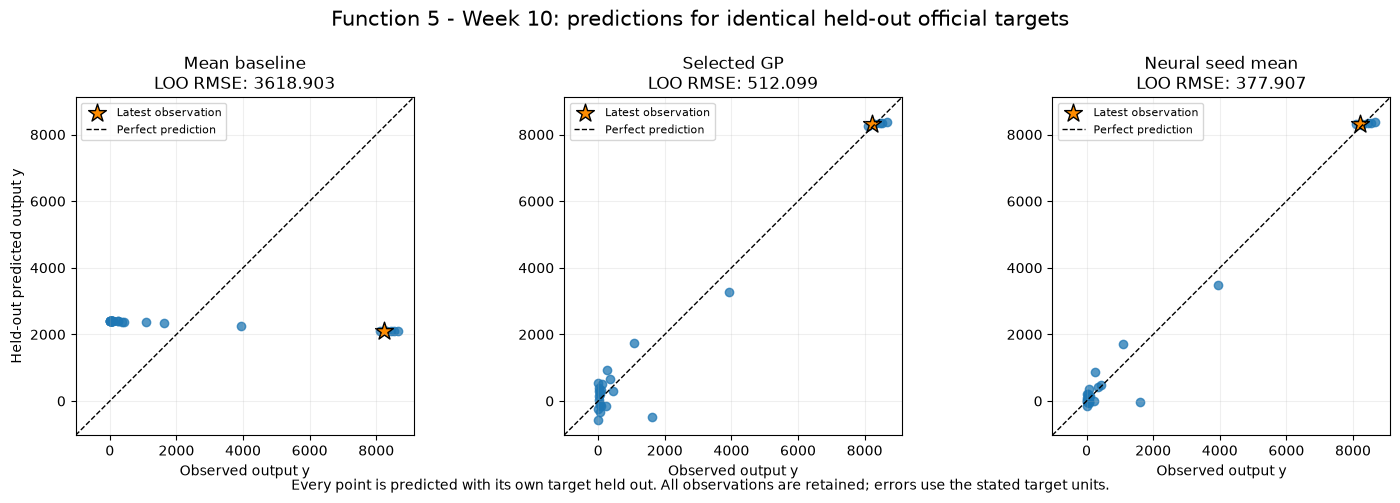

,Model,Latest held-out prediction,Latest error,Latest absolute error (%),Latest share of squared error (%),Other rows LOO RMSE
0,Neural seed mean,8303.717832,80.508741,0.979043,0.156502,384.294661
1,Selected GP,8309.660740,86.451650,1.051313,0.098275,520.906793


In [6]:
display(plot_held_out_comparison(
    {"Mean baseline": run["predictions"]["Mean baseline"],
     "Selected GP": selected_predictions, "Neural seed mean": networks["predictions"]},
    target, model_names=["Mean baseline", "Selected GP", "Neural seed mean"],
    latest_mask=review["latest_mask"], target_label=TARGET_LABEL,
    title=f"{TITLE}: predictions for identical held-out official targets",
    save_to=FIGURES_DIR / "model-validation.png"))
display(review_latest_predictions({"Selected GP": selected_predictions,
    "Neural seed mean": networks["predictions"]}, target, review["latest_mask"]).round(6))


### Review the next query on a common candidate pool

Retain the seeded broad and incumbent-local candidate searches, six-decimal bounds and duplicate exclusions. The geometric comparator is the farthest eligible point in this frozen pool; it is a finite-pool coverage proxy. Neural alternatives maximise mean predictions across seeds. GP UCB uses latent posterior SD. Neither score is a new function evaluation.

In [7]:
candidates, coverage_point = make_candidate_review(inputs, anchor,
    input_columns=INPUT_COLUMNS, search_settings=SEARCH_SETTINGS,
    minimum_distance=MIN_QUERY_DISTANCE, excluded_inputs=known_inputs)
query_run = review_gp_query(selected, candidates, known_inputs, target,
    input_columns=INPUT_COLUMNS, weights=EXPLORATION_WEIGHTS, weight=EXPLORATION_WEIGHT,
    feature_sets=FEATURE_SETS, minimum_distance=MIN_QUERY_DISTANCE, training_inputs=fit_inputs)
proposal, scored = query_run["proposal"], query_run["scores"]
next_query = np.asarray(proposal["point"])
neural_proposal = neural_candidate_review(networks, candidates, input_columns=INPUT_COLUMNS)
display(pd.Series(proposal))
display(pd.Series(neural_proposal))
display(scored.head(5)[[*INPUT_COLUMNS, "posterior_mean", "posterior_sd", "ucb", "candidate_source", "nearest_observed_distance"]])


point                         [0.999999, 0.999999, 0.999999, 0.959224]
predicted_output                                           8219.936577
posterior_std                                               162.165579
ucb                                                        8537.781112
predicted_mean_improvement                                 -442.468425
inside_sampled_hull                                              False
portal_input                       0.999999-0.999999-0.999999-0.959224
nearest_observed_distance                                     0.020412
dtype: object

point                          [0.979763, 0.979015, 0.999999, 0.999999]
predicted_target                                            8211.844554
seed_prediction_sd                                            14.418641
architecture                                                     tanh-8
portal_input                        0.979763-0.979015-0.999999-0.999999
criterion             mean prediction across all declared seeds; not...
dtype: object

,x1,x2,x3,x4,posterior_mean,posterior_sd,ucb,candidate_source,nearest_observed_distance
0,0.999999,0.999999,0.999999,0.959224,8219.936577,162.165579,8537.781112,Near incumbent,0.020412
1,0.999999,0.999999,0.999999,0.958574,8216.624798,163.023226,8536.150321,Near incumbent,0.021062
2,0.999999,0.999999,0.999999,0.958286,8215.156116,163.406061,8535.431995,Near incumbent,0.021350
3,0.999999,0.999999,0.999999,0.957656,8211.940576,164.249479,8533.869554,Near incumbent,0.021980
4,0.999999,0.999999,0.999999,0.956782,8207.473295,165.432878,8531.721736,Near incumbent,0.022854


In [8]:
# Use the same frozen pool and mean/SD values for every exploration weight.
display(query_run["weight_sensitivity"].round(6))
scope_proposals = {"selected": {"scope": selected["scope"], "model": selected["name"], **proposal}}
if peer_run is not None:
    alternative = (dict(official_gp, scope="official") if selected["scope"] != "official" else
                   choose_training_scope(run, GP_NAMES, peer_run=peer_run, metric=SELECTION_METRIC))
    # If the official fit won, still record the best peer-assisted GP's common-pool alternative.
    if selected["scope"] == "official":
        col = "Peer-assisted " + SELECTION_METRIC
        peer_name = peer_run["table"].set_index("Model")[col].idxmin()
        alternative = dict(name=peer_name, model=peer_run["fitted"][peer_name], scope="official_plus_retained_peers")
    alternative_inputs = known_inputs if alternative["scope"] != "official" else inputs
    alt = review_gp_query(alternative, candidates, known_inputs, target, input_columns=INPUT_COLUMNS,
        weights=EXPLORATION_WEIGHTS, weight=EXPLORATION_WEIGHT, feature_sets=FEATURE_SETS,
        minimum_distance=MIN_QUERY_DISTANCE, training_inputs=alternative_inputs)
    scope_proposals["alternative"] = {"scope": alternative["scope"], "model": alternative["name"], **alt["proposal"]}
    display(pd.DataFrame(scope_proposals).T)
regularisation_review = None
if FUNCTION_NUMBER in (2, 5, 6, 7, 8):
    training_target = np.r_[target, peer_target] if selected["scope"] != "official" else target
    regularisation_review = noise_sensitivity(selected_model, fit_inputs, training_target, next_query,
        fractions=(.03, .10, .30), fitted_noise_fraction=.10)
    display(regularisation_review.rename(columns={"Assumed noise fraction": "GP regularisation fraction"}).round(6))
if FUNCTION_NUMBER == 5:
    from scipy.spatial.distance import cdist
    all_candidates, _ = make_candidate_review(inputs, anchor, input_columns=INPUT_COLUMNS,
        search_settings=SEARCH_SETTINGS, minimum_distance=0.)
    from model_review_helpers import score_review_candidates
    spacing_scores = score_review_candidates(selected_model, all_candidates,
        input_columns=INPUT_COLUMNS, weight=EXPLORATION_WEIGHT)
    spacing_rows = []
    for minimum in (0., .01, .02, .05):
        top = spacing_scores.loc[spacing_scores.nearest_observed_distance >= minimum].iloc[0]
        spacing_rows.append({"Minimum distance": minimum,
            "Portal input": "-".join(f"{top[c]:.6f}" for c in INPUT_COLUMNS),
            "Nearest observed distance": top.nearest_observed_distance,
            "Predicted target": top.posterior_mean, "UCB": top.ucb})
    spacing_review = pd.DataFrame(spacing_rows)
    display(spacing_review)


,Weight,x1,x2,x3,x4,Predicted output,Posterior SD
0,0.00,0.999999,0.999999,0.999999,0.959224,8219.936577,162.165579
1,1.00,0.999999,0.999999,0.999999,0.959224,8219.936577,162.165579
2,1.96,0.999999,0.999999,0.999999,0.959224,8219.936577,162.165579
3,3.00,0.999999,0.999999,0.999999,0.959224,8219.936577,162.165579


,GP regularisation fraction,Predicted output,Posterior SD
0,0.03,8224.252433,93.877977
1,0.10,8219.936577,162.165579
2,0.30,8056.024088,405.575511


,Minimum distance,Portal input,Nearest observed distance,Predicted target,UCB
0,0.00,0.999999-0.999999-0.999942-0.999999,0.000057,8418.963632,8681.474767
1,0.01,0.999999-0.999999-0.999999-0.989835,0.010164,8371.169396,8636.195305
2,0.02,0.999999-0.999999-0.999999-0.959224,0.020412,8219.936577,8537.781112
3,0.05,0.999999-0.999999-0.999999-0.929102,0.050534,8062.245680,8471.757449


### Inspect conditional responses and neural input gradients

Every omitted coordinate is held fixed. Only measurements actually on a slice are plotted on its curve. The GP band and neural seed band describe different quantities. Input gradients are checked against finite differences and describe a fitted model, not causal effects.

At a near-zero ReLU activation, central differences may cross a kink. Such anchor checks are marked explicitly; implementation checks then use a declared nearby smooth probe. The anchor derivative is not presented as validated.

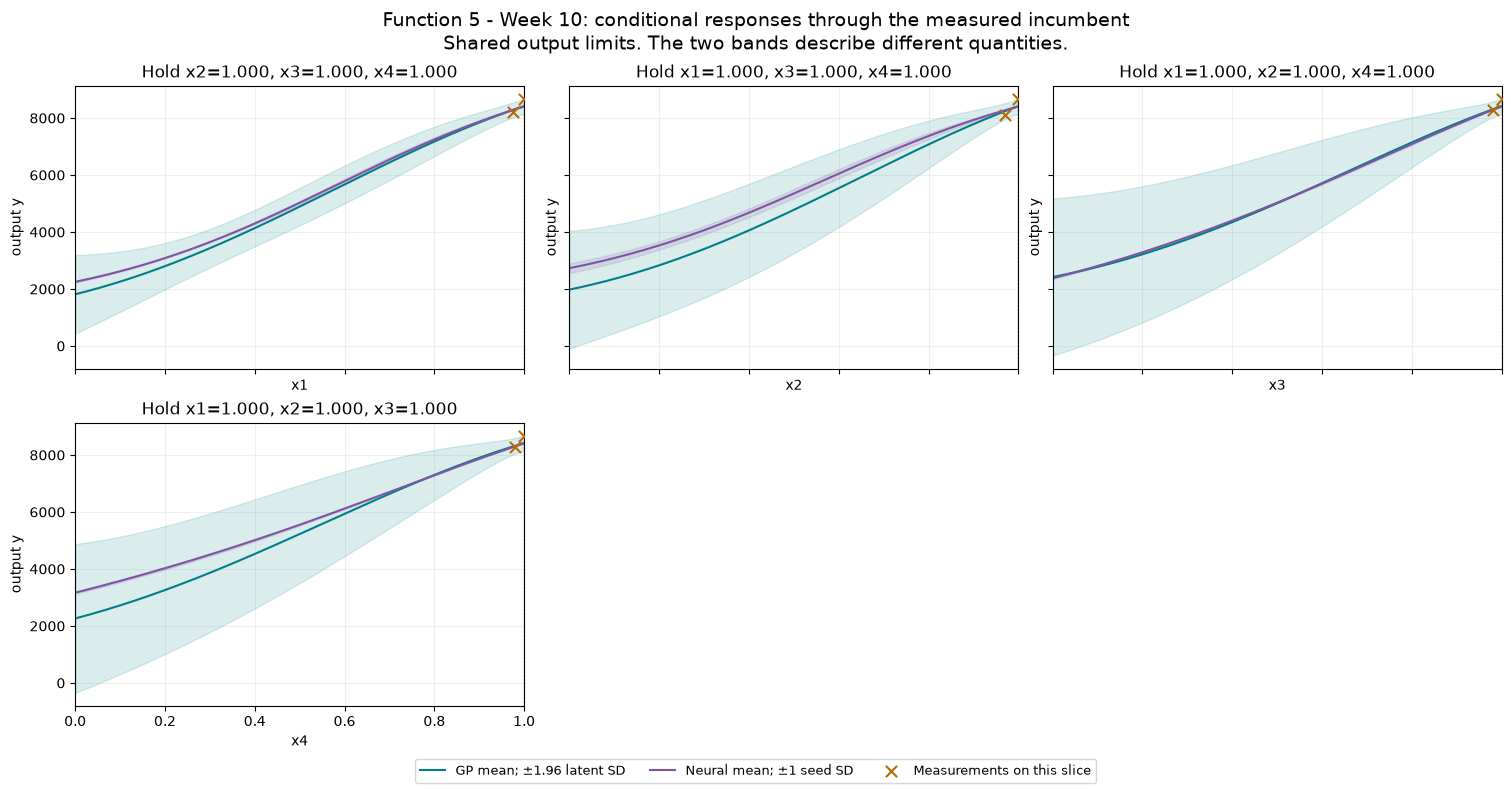

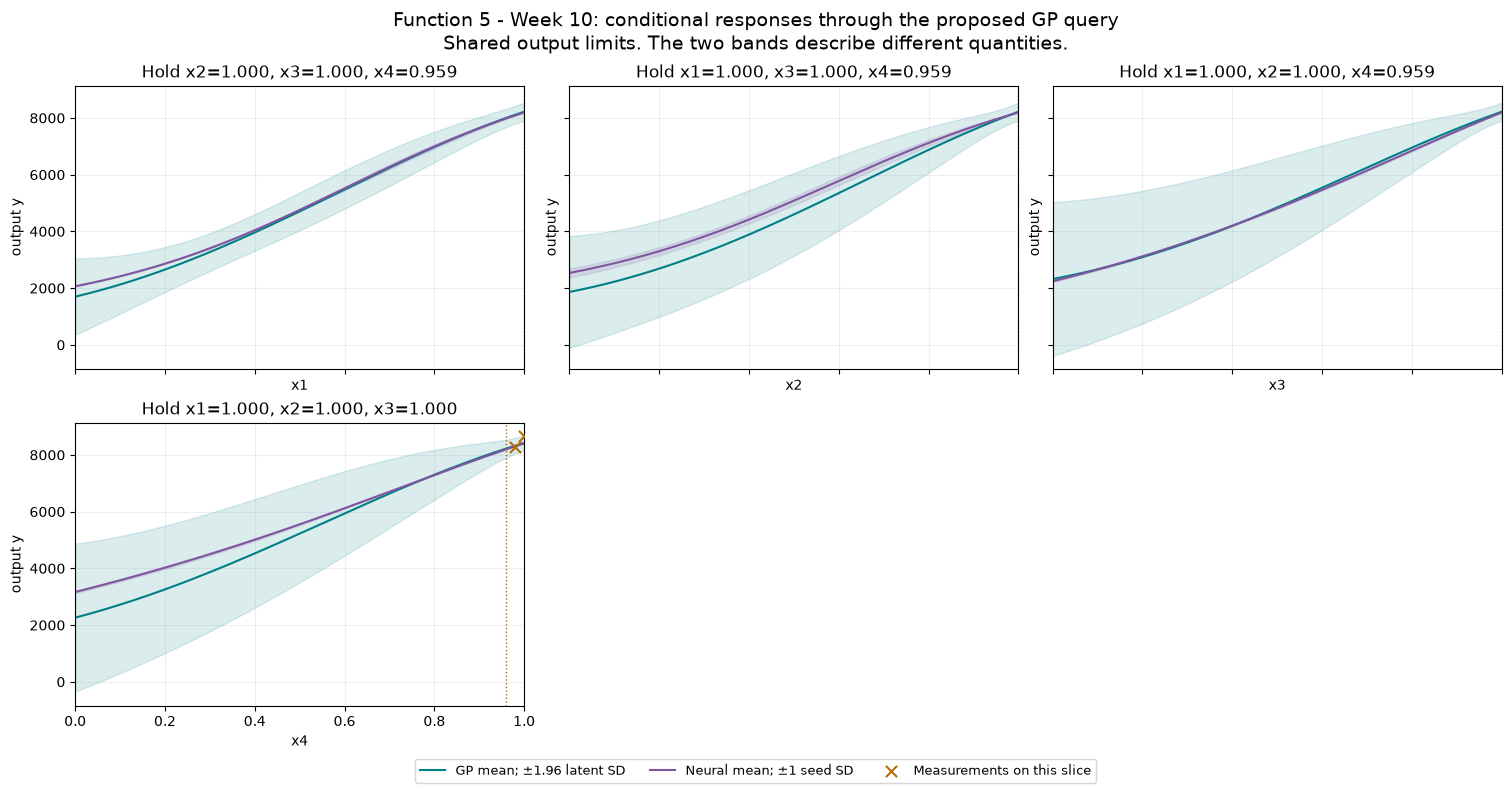

,Model,maximum_relative_error,passes,check_location,check_point,anchor_relative_error,anchor_check_passes
0,NN tanh-8 seed 11,0.000008,True,anchor,"[0.999999, 0.999999, 0.999999, 0.999999]",0.000008,True
1,NN tanh-8 seed 42,0.000011,True,anchor,"[0.999999, 0.999999, 0.999999, 0.999999]",0.000011,True
2,NN tanh-8 seed 73,0.000011,True,anchor,"[0.999999, 0.999999, 0.999999, 0.999999]",0.000011,True


,x1,x2,x3,x4
Model,,,,
NN tanh-8 seed 11,5577.674425,5175.085759,6540.994604,5468.279240
NN tanh-8 seed 42,4538.656799,3920.190497,5907.477734,5108.949532
NN tanh-8 seed 73,4530.209626,3908.257316,5896.124503,5103.493649


In [9]:
display(plot_response_profiles(selected_model, networks["models"], inputs, target, anchor,
    input_columns=INPUT_COLUMNS, target_label=TARGET_LABEL,
    title=f"{TITLE}: conditional responses through the measured incumbent",
    save_to=FIGURES_DIR / "model-response-incumbent.png"))
display(plot_response_profiles(selected_model, networks["models"], inputs, target, next_query,
    input_columns=INPUT_COLUMNS, target_label=TARGET_LABEL,
    title=f"{TITLE}: conditional responses through the proposed GP query",
    save_to=FIGURES_DIR / "model-response-proposal.png"))
if len(INPUT_COLUMNS) <= 3:
    display(plot_score_planes(selected_model, fit_inputs, next_query, input_columns=INPUT_COLUMNS,
        target_label=TARGET_LABEL, title=f"{TITLE}: proposed-query score planes",
        weight=EXPLORATION_WEIGHT, save_to=FIGURES_DIR / "model-query-planes.png"))
gradient_review = neural_gradient_review(networks, anchor)
display(gradient_review.drop(columns="gradient"))
if not gradient_review.passes.all():
    raise ValueError("A neural input-gradient parity check failed; inspect before interpreting it")
display(pd.DataFrame([row for row in gradient_review.gradient], columns=INPUT_COLUMNS,
                     index=gradient_review.Model))


### Interactive GP and neural input explorer

[Open the offline explorer](figures/neural-network-explorer.html). Change any input, choose a neural architecture, compare its three seeds with the GP, or reset to the measured incumbent or proposed query. Curves update from exported fitted weights. This tool performs no training, course evaluations or submissions.

In [10]:
gp_error = f"{selected['error']:.6g}"
validation_text = (f"Selected GP {SELECTION_METRIC} on official targets: {gp_error}. "
    f"Neural seed-mean {SELECTION_METRIC}: {neural_metrics[SELECTION_METRIC]:.6g}. "
    f"Network architecture selected by average error across seeds {SEEDS}.")
explorer = save_neural_explorer(FIGURES_DIR / "neural-network-explorer.html",
    models=run["fitted"], metadata=neural_metadata, selected_architecture=networks["architecture"],
    gp=selected_model, input_columns=INPUT_COLUMNS, anchor=anchor, proposal=next_query,
    title=f"{TITLE}: GP and neural input explorer", target_label=TARGET_LABEL,
    scope=selected["scope"], validation=validation_text)
# Check exported forward passes at observations, new proposals and domain boundaries.
test_points = np.vstack([inputs, next_query, np.zeros(len(INPUT_COLUMNS)), np.full(len(INPUT_COLUMNS), .999999)])
for architecture, specs in explorer["networks"].items():
    for spec in specs:
        name = next(name for name, settings in neural_metadata.items()
                    if settings["architecture"] == architecture and settings["seed"] == spec["seed"])
        np.testing.assert_allclose(network_prediction(spec, test_points), run["fitted"][name].predict(test_points), rtol=1e-10, atol=1e-9)
expected_mean, expected_sd = selected_model.predict(test_points, return_std=True)
actual_mean, actual_sd = gp_prediction(explorer["gp"], test_points)
np.testing.assert_allclose(actual_mean, expected_mean, rtol=1e-10, atol=1e-9)
np.testing.assert_allclose(actual_sd, expected_sd, rtol=1e-9, atol=1e-9)
print("Exported GP/neural predictions match the fitted Python models.")


Exported GP/neural predictions match the fitted Python models.


In [11]:
magnitude_review = None
if FUNCTION_NUMBER == 1:
    # Fit a separate activity explanation; it cannot choose the signed-score proposal.
    magnitude_models = {"Mean baseline": models["Mean baseline"], **{name: models[name] for name in GP_NAMES}}
    magnitude_review = evaluate_regressors(magnitude_models, inputs, np.abs(target))
    display(magnitude_review["table"].sort_values(SELECTION_METRIC).round(6))
    print("Magnitude explains activity only. The proposed query above maximises signed-score GP UCB.")


### Save a provisional proposal

Four query opportunities remain, including Week 10. The held-out estimates are retrospective and use the same official targets across models.

In [12]:
selected_gp = selected_model.steps[-1][1] if hasattr(selected_model, "steps") else selected_model
summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "analysis": "week_10_model_review",
    "observations": len(inputs), "official_observations": len(inputs), "retained_peer_observations": len(peer_inputs),
    "python_executable": sys.executable, "target_units": TARGET_LABEL, "height_scale": HEIGHT_SCALE,
    "best_observed_raw_output": float(raw_y.max()), "best_observed_target": float(target.max()),
    "query_model": selected["name"], "training_scope": selected["scope"],
    "selection_metric": SELECTION_METRIC, "official_target_error": selected["error"],
    "baseline_error": float(run["table"].set_index("Model").loc["Mean baseline", SELECTION_METRIC]),
    "proposal_status": "proposed_not_submitted", "remaining_queries": remaining_queries(WEEK_DIR),
    "portal_input": proposal["portal_input"], "point": proposal["point"], "proposal": proposal,
    "proposal_target_units": TARGET_LABEL, "ucb_weight": EXPLORATION_WEIGHT,
    "candidate_count": len(candidates), "minimum_query_distance": MIN_QUERY_DISTANCE,
    "coverage_proxy_point": coverage_point.tolist(), "search_settings": SEARCH_SETTINGS,
    "fitted_kernel": str(selected_gp.kernel_), "model_settings": MODEL_SETTINGS,
    "model_comparison": run["table"].to_dict(orient="records"),
    "model_warnings": run["warnings"], "held_out_predictions": {k: v.tolist() for k,v in run["predictions"].items()},
    "peer_comparison": None if peer_run is None else peer_run["table"].to_dict(orient="records"),
    "peer_warnings": None if peer_run is None else peer_run["warnings"],
    "scope_proposals": scope_proposals, "weight_sensitivity": query_run["weight_sensitivity"].to_dict(orient="records"),
    "regularisation_sensitivity": None if regularisation_review is None else regularisation_review.to_dict(orient="records"),
    "neural_architectures": ARCHITECTURES, "neural_seeds": SEEDS, "neural_settings": NEURAL_SETTINGS,
    "neural_architecture_comparison": networks["table"].to_dict(orient="records"),
    "selected_neural_architecture": networks["architecture"], "neural_ensemble_errors": neural_metrics,
    "neural_proposal": neural_proposal, "neural_gradient_checks": gradient_review.to_dict(orient="records"),
    "magnitude_comparison": None if magnitude_review is None else magnitude_review["table"].to_dict(orient="records"),
    "snapshot_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "cohort_audit_sha256": None if COHORT_PATH is None else hashlib.sha256(COHORT_AUDIT_PATH.read_bytes()).hexdigest(),
}
if FUNCTION_NUMBER == 5:
    summary["spacing_sensitivity"] = spacing_review.to_dict(orient="records")
text = json.dumps(summary, indent=2, allow_nan=False)
(ANALYSIS_DIR / "model-review.json").write_text(text + "\n", encoding="utf-8")
print(text)


{
  "function": 5,
  "week": 10,
  "analysis": "week_10_model_review",
  "observations": 29,
  "official_observations": 29,
  "retained_peer_observations": 0,
  "python_executable": "C:\\_Source\\Imperial-ML-AI-Live\\Capstone\\imperial-capstone\\.venv\\Scripts\\python.exe",
  "target_units": "output y",
  "height_scale": null,
  "best_observed_raw_output": 8662.405001248297,
  "best_observed_target": 8662.405001248297,
  "query_model": "Gaussian process",
  "training_scope": "official",
  "selection_metric": "LOO RMSE",
  "official_target_error": 512.0985465827476,
  "baseline_error": 3618.9029367887924,
  "proposal_status": "proposed_not_submitted",
  "remaining_queries": 4,
  "portal_input": "0.999999-0.999999-0.999999-0.959224",
  "point": [
    0.999999,
    0.999999,
    0.999999,
    0.959224
  ],
  "proposal": {
    "point": [
      0.999999,
      0.999999,
      0.999999,
      0.959224
    ],
    "predicted_output": 8219.936576550113,
    "posterior_std": 162.16557926243067,


### My data only alternatives

The blend reduced outer-fold RMSE from 589 to 382 and later-return RMSE from 844 to 578. Four inner grouped folds select one GP, one non-GP partner and a GP weight of 0.25, 0.50 or 0.75. For the final fit this selection uses all official observations with inner split seed 42. Candidate spacing follows the weekly minimum of 0.02.

Fit, validate and search using only the official snapshot. Use the weekly Sobol and near-incumbent search, portal precision and spacing rule. A Matérn GP uses the weekly UCB weight of 1.96. Other alternatives choose the largest predicted mean on the eligible pool. The full-cohort GP point comes from the saved comparison. The tables show the original official GP's prediction at each point and the alternative's predicted score at both archived points. [Week 10 query review](../../../results/week-10-review.md)

In [13]:
from official_query_alternatives import review_official_alternatives

alternatives = ('Nested GP blend',)
original_gp_proposal = next(row for row in scope_proposals.values() if row["scope"] == "official")
cohort_archive_path = WEEK_DIR / "full-cohort/model-review.json"
cohort_gp_proposal = None
if cohort_archive_path.is_file():
    archive = json.loads(cohort_archive_path.read_text(encoding="utf-8"))
    if (archive["function"], archive["week"], archive["official_snapshot_sha256"]) != (
        FUNCTION_NUMBER, CURRENT_WEEK, summary["snapshot_sha256"]
    ):
        raise ValueError("The saved cohort proposal belongs to a different official snapshot")
    if archive["owner"]["proposal"]["portal_input"] != original_gp_proposal["portal_input"]:
        raise ValueError("The owner-only proposal differs from the saved scope comparison")
    cohort_gp_proposal = {"model": archive["cohort"]["model"], **archive["cohort"]["proposal"]}

alternative_review = review_official_alternatives(
    inputs, target, data.source_round.to_numpy() > 0,
    {name: models[name] for name in GP_NAMES}, official_gp, original_gp_proposal, cohort_gp_proposal,
    alternatives, columns=INPUT_COLUMNS, search=SEARCH_SETTINGS, feature_sets=FEATURE_SETS,
    metric="MAE" if SELECTION_METRIC == "LOO MAE" else "RMSE", minimum_distance=MIN_QUERY_DISTANCE,
    weight=EXPLORATION_WEIGHT, weights=EXPLORATION_WEIGHTS,
)
alternative_review.update(function=FUNCTION_NUMBER, week=CURRENT_WEEK, training_scope="official",
    official_rows=len(inputs), official_snapshot_sha256=summary["snapshot_sha256"],
    target_units=TARGET_LABEL, metric="MAE" if SELECTION_METRIC == "LOO MAE" else "RMSE",
    proposal_status="proposed_not_submitted")
(ANALYSIS_DIR / "alternative-query-review.json").write_text(
    json.dumps(alternative_review, indent=2, allow_nan=False) + "\n", encoding="utf-8")
display(pd.DataFrame(alternative_review["validation"]).rename(columns={
    "policy": "Model", "mean_error": "Mean outer error", "mean_returned_error": "Later-return error",
    "mean_selection_gap": "Mean shortlist gap", "best_picks": "Best picks out of 10",
    "seed_42_error": "Split 42 error", "seed_73_error": "Split 73 error",
}).round(6))
comparison = pd.DataFrame(alternative_review["proposals"])
with pd.option_context("display.max_colwidth", None):
    display(comparison[["source", "model", "criterion", "portal_input", "nearest_official_distance",
                        "distance_to_original_gp", "distance_to_full_cohort_gp"]].round(6))
display(comparison[["source", "model", "predicted_target", "latent_sd", "original_gp_mean",
                    "original_gp_ucb", "predicted_target_at_original_gp",
                    "predicted_target_at_full_cohort_gp"]].round(6))
for row in alternative_review["proposals"]:
    if "gp_weight" in row.get("details", {}):
        details = row["details"]
        display(pd.Series({"GP": details["gp"], "Partner": details["partner"],
                           "GP weight": details["gp_weight"], "Inner split seed": details["inner_split_seed"]}))


,Model,Mean outer error,Later-return error,Mean shortlist gap,Best picks out of 10,Split 42 error,Split 73 error
0,Saved GP family,544.224664,743.858776,10.945894,9,488.034784,600.414544
1,Nested GP blend,480.531621,768.381411,5.200034,9,378.992361,582.070882


,source,model,criterion,portal_input,nearest_official_distance,distance_to_original_gp,distance_to_full_cohort_gp
0,Original My data only GP,Gaussian process,GP UCB (1.96),0.999999-0.999999-0.999999-0.959224,0.020412,0.000000,0.000000
1,Full-cohort GP,Gaussian process,GP UCB (1.96),0.999999-0.999999-0.999999-0.959224,0.020412,0.000000,0.000000
2,My data only alternative,Nested GP blend,Predicted mean,0.979763-0.979015-0.999999-0.999999,0.021282,0.050124,0.050124


,source,model,predicted_target,latent_sd,original_gp_mean,original_gp_ucb,predicted_target_at_original_gp,predicted_target_at_full_cohort_gp
0,Original My data only GP,Gaussian process,8219.936577,162.165579,8219.936577,8537.781112,NaN,NaN
1,Full-cohort GP,Gaussian process,8141.965548,171.381111,8219.936577,8537.781112,NaN,NaN
2,My data only alternative,Nested GP blend,8206.984637,NaN,8186.762207,8451.487068,8197.024587,8197.024587


GP                         GP Matérn 3/2
Partner             Tanh-8 seed ensemble
GP weight                           0.25
Inner split seed                      42
dtype: object

### Course lifecycle for this review

1. **Define the goal and scope** — give the project owner comparable model evidence for a single provisional Week 10 query, including the supported official-only alternatives.
2. **Gather the data** — use the independent official snapshot and the retained peer rows where they were part of the weekly comparison.
3. **Explore the data** — read the companion measured review for ranks, input patterns and the round 9 forecast check.
4. **Clean and preprocess the data** — validate the snapshots and fit scalers inside each held-out training fold.
5. **Select and engineer features** — use the declared continuous coordinates and feature subsets. Function 1 uses the signed-log target, with a separate magnitude diagnostic.
6. **Define the machine-learning task** — regress the continuous score as a surrogate for bounded black-box maximisation.
7. **Partition the data** — leave one official row out per fold. Peer-assisted GP fits keep the same official validation targets. Check the official-only alternatives in two grouped five-fold repeats.
8. **Select and train candidate methods** — refit the declared GP, regression and neural comparators, and assess the supported official-only alternatives with the recorded splits.
9. **Evaluate and interpret the results** — compare against the mean baseline and review held-out error, shortlist ranking, and candidate coordinates for the official and cohort suggestions.
10. **Deploy and iterate** — deployment is not applicable to this course review. Save provisional evidence for the next decision and compare it with future feedback.
